In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv("../data/cleaned/ecommerce_cleaned.csv",
                 parse_dates=["order_purchase_timestamp", "order_delivered_customer_date",
                              "order_estimated_delivery_date"])
df.shape

(112650, 29)

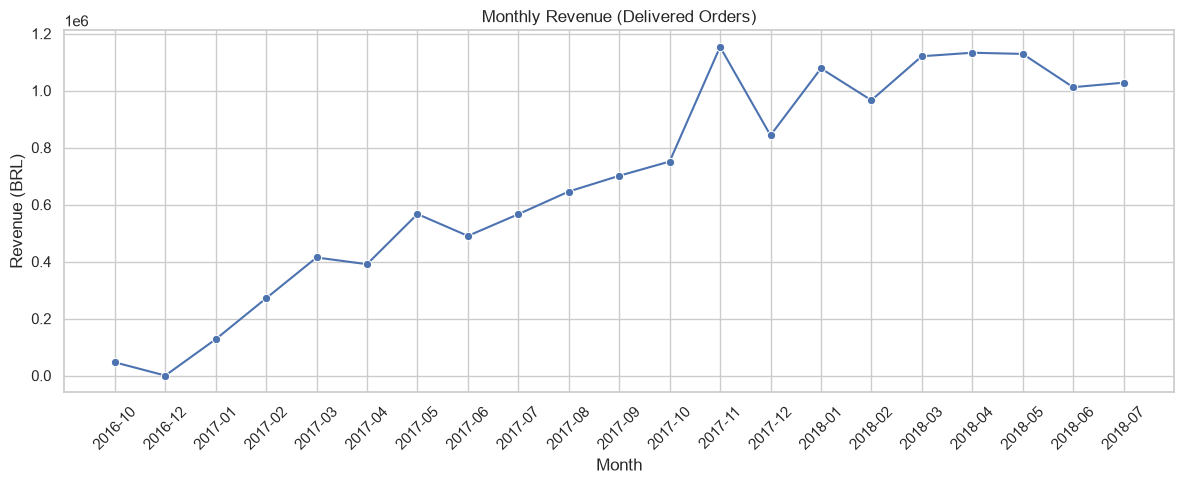

In [2]:
monthly = (df[df["order_status"] == "delivered"]
           .groupby("purchase_year_month")["revenue"].sum().reset_index())

# drop the first and last months, which are incomplete in this dataset
monthly = monthly.iloc[1:-1]

plt.figure(figsize=(12, 5))
sns.lineplot(data=monthly, x="purchase_year_month", y="revenue", marker="o")
plt.xticks(rotation=45)
plt.title("Monthly Revenue (Delivered Orders)")
plt.xlabel("Month")
plt.ylabel("Revenue (BRL)")
plt.tight_layout()
plt.show()

**Takeaway:** Monthly revenue grew steadily from early 2017, peaked in November 2017 (about 1.15M BRL, likely Black Friday), and then plateaued around 1.0-1.1M BRL through mid-2018, suggesting growth slowed once the business matured.

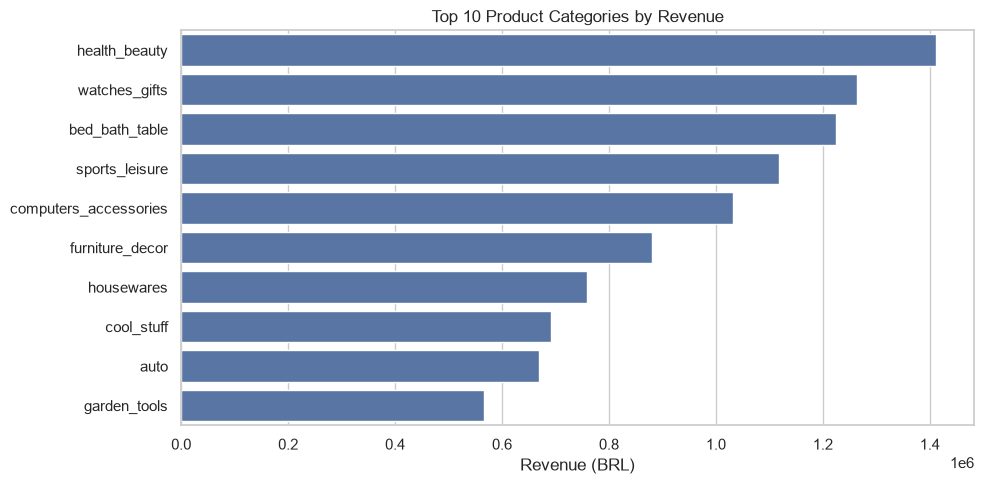

In [3]:
top_cat = (df[df["order_status"] == "delivered"]
           .groupby("product_category_name_english")["revenue"].sum()
           .sort_values(ascending=False).head(10).reset_index())

plt.figure(figsize=(10, 5))
sns.barplot(data=top_cat, y="product_category_name_english", x="revenue", color="#4C72B0")
plt.title("Top 10 Product Categories by Revenue")
plt.xlabel("Revenue (BRL)")
plt.ylabel("")
plt.tight_layout()
plt.show()

**Takeaway:** Revenue is spread across several categories rather than dominated by one. Watches/gifts, bed/bath/table, sports/leisure and computers/accessories each bring in roughly 1.0-1.3M BRL.

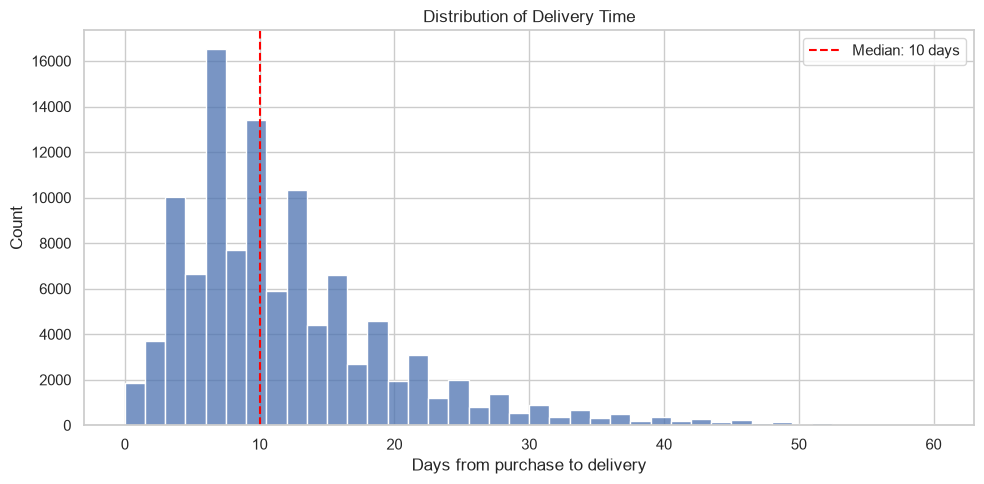

In [4]:
delivered = df[(df["order_status"] == "delivered") & df["delivery_days"].notna()].copy()
delivered = delivered[delivered["delivery_days"] <= 60]

plt.figure(figsize=(10, 5))
sns.histplot(delivered["delivery_days"], bins=40, color="#4C72B0")
plt.axvline(delivered["delivery_days"].median(), color="red", linestyle="--",
            label=f"Median: {delivered['delivery_days'].median():.0f} days")
plt.title("Distribution of Delivery Time")
plt.xlabel("Days from purchase to delivery")
plt.legend()
plt.tight_layout()
plt.show()

**Takeaway:** The median delivery time is 10 days and most orders arrive within 4-15 days, but a long tail of orders takes 25+ days. Reducing these slow deliveries is the biggest logistics opportunity.

                 mean  count
delivery_status             
Late             2.27   6381
On time / early  4.29  89443


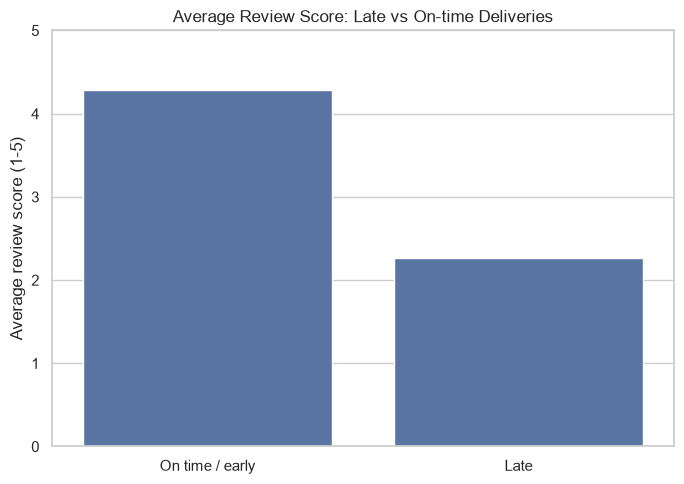

In [5]:
rev = df[(df["order_status"] == "delivered")
         & df["delay_days"].notna()
         & df["review_score"].notna()].copy()

# one row per order, so orders with many items don't count more than once
rev = rev.drop_duplicates("order_id")

rev["delivery_status"] = np.where(rev["delay_days"] > 0, "Late", "On time / early")

summary = rev.groupby("delivery_status")["review_score"].agg(["mean", "count"]).round(2)
print(summary)

plt.figure(figsize=(7, 5))
sns.barplot(data=rev, x="delivery_status", y="review_score", color="#4C72B0", errorbar=None)
plt.title("Average Review Score: Late vs On-time Deliveries")
plt.xlabel("")
plt.ylabel("Average review score (1-5)")
plt.ylim(0, 5)
plt.tight_layout()
plt.show()

**Takeaway:** Orders delivered after the estimated date average a review score of 2.27, versus 4.29 for on-time orders. Although only about 7% of orders are late, they are strongly associated with poor customer satisfaction, so improving delivery reliability should be a priority.

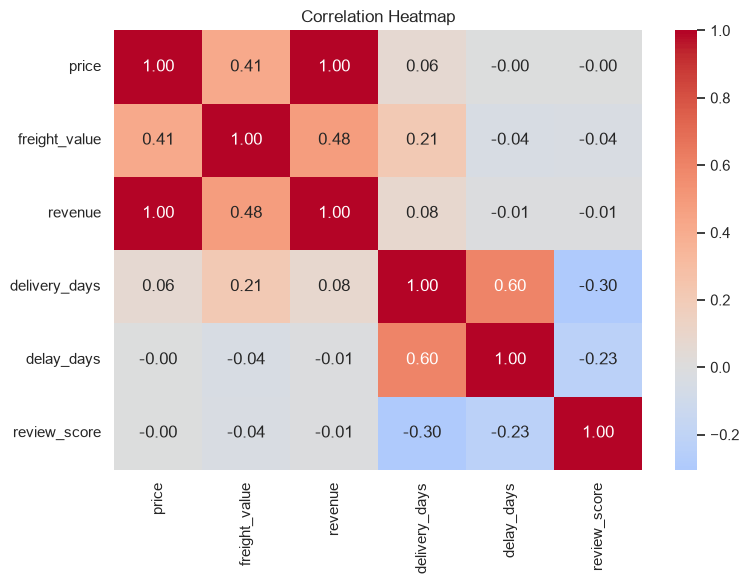

In [6]:
num_cols = ["price", "freight_value", "revenue", "delivery_days", "delay_days", "review_score"]
corr = df[num_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

**Takeaway:** Review score is negatively correlated with delivery time (-0.30) and delay versus the estimate (-0.23), while price and revenue show almost no relationship with satisfaction. Customers care more about how fast and reliably an order arrives than how much they spent.